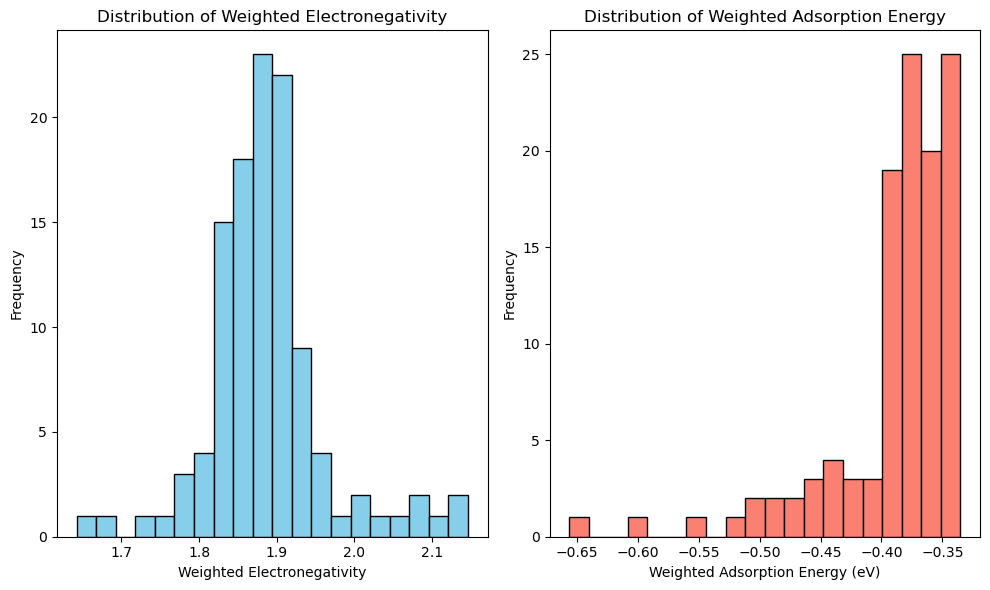

In [1]:
import os
import json
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# =========================
# Paths
# =========================
BO_DIR = r"./"
EH_PATH = r"./EH_extra.xlsx"

# =========================
# Step 1: 每个 JSON → DataFrame → 合并
# =========================
dfs = []

for fp in sorted(glob.glob(os.path.join(BO_DIR, "*.json"))):
    with open(fp, "r", encoding="utf-8") as f:
        obj = json.load(f)

    # ⭐ 关键：你的 JSON = 列字典
    df_i = pd.DataFrame(obj)
    df_i["_source_file"] = os.path.basename(fp)
    dfs.append(df_i)

if not dfs:
    raise RuntimeError("No valid JSON files loaded.")

df = pd.concat(dfs, ignore_index=True)

# =========================
# Step 2: 计算百分含量
# =========================
for col in ["volume1", "volume2", "separation_coefficient"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

denom = df["volume1"] + df["volume2"]
df["frac1"] = df["volume1"] / denom
df["frac2"] = df["volume2"] / denom

df.loc[denom == 0, ["frac1", "frac2"]] = np.nan

# =========================
# Step 3: 读取 EH_extra.xlsx → 电负性映射
# =========================
eh = pd.read_excel(EH_PATH)

metal_col = eh.columns[0]  # 第一列是 metal
if "electronegativity" not in eh.columns:
    raise KeyError("EH_extra.xlsx 中未找到 electronegativity 列")

eh_map = (
    eh[[metal_col, "electronegativity"]]
    .dropna()
    .assign(**{metal_col: lambda x: x[metal_col].astype(str).str.strip()})
    .set_index(metal_col)["electronegativity"]
    .to_dict()
)

df["substance1"] = df["substance1"].astype(str).str.strip()
df["substance2"] = df["substance2"].astype(str).str.strip()

df["en1"] = df["substance1"].map(eh_map)
df["en2"] = df["substance2"].map(eh_map)

# =========================
# Step 4: 计算加权电负性
# =========================
df["weighted_electronegativity"] = (
    df["en1"] * df["frac1"] + df["en2"] * df["frac2"]
)

# =========================
# Step 5: 读取并合并“Sheet2”中的吸附自由能数据
# =========================
sheet2 = pd.read_excel(EH_PATH, sheet_name="Sheet2")
sheet2 = sheet2.rename(columns={"Unnamed: 0": "element"})
sheet2["element"] = sheet2["element"].ffill()  # Fill the metal column if missing
ads_avg = (
    sheet2.groupby("element")["Free Energy of Adsorption (eV)"]
    .mean()
    .reset_index()
    .rename(columns={"Free Energy of Adsorption (eV)": "FE_ads_avg"})
)

# Merge averaged adsorption data with the existing dataframe for both substances
df = pd.merge(df, ads_avg, left_on="substance1", right_on="element", how="left")
df = pd.merge(df, ads_avg, left_on="substance2", right_on="element", how="left", suffixes=('_substance1', '_substance2'))

# Fill missing values with 0 (or NaN based on your preference)
df["FE_ads_avg_substance1"] = df["FE_ads_avg_substance1"].fillna(0)
df["FE_ads_avg_substance2"] = df["FE_ads_avg_substance2"].fillna(0)

# =========================
# Step 6: 计算加权吸附自由能 (Weighted Adsorption Energy)
# =========================
df["weighted_FE_ads_avg"] = (
    df["FE_ads_avg_substance1"] * df["frac1"] + df["FE_ads_avg_substance2"] * df["frac2"]
)

# =========================
# Step 7: 作图 + 相关系数
# =========================
plot_df = df[["weighted_electronegativity", "separation_coefficient", "weighted_FE_ads_avg"]].dropna()

# Plot the distribution of weighted electronegativity and weighted FE_ads_avg
plt.figure(figsize=(10, 6))

# Weighted electronegativity distribution
plt.subplot(1, 2, 1)
plt.hist(plot_df["weighted_electronegativity"], bins=20, color='skyblue', edgecolor='black')
plt.xlabel("Weighted Electronegativity")
plt.ylabel("Frequency")
plt.title("Distribution of Weighted Electronegativity")

# Weighted Adsorption Energy distribution
plt.subplot(1, 2, 2)
plt.hist(plot_df["weighted_FE_ads_avg"], bins=20, color='salmon', edgecolor='black')
plt.xlabel("Weighted Adsorption Energy (eV)")
plt.ylabel("Frequency")
plt.title("Distribution of Weighted Adsorption Energy")

plt.tight_layout()
plt.show()

# =========================
# （可选）保存完整结果
# =========================
# out_path = os.path.join(BO_DIR, "merged_weighted_electronegativity_adsorption.xlsx")
# df.to_excel(out_path, index=False)

In [2]:
df

,substance1,volume1,substance2,volume2,substance3,volume3,substance4,volume4,syn_completed,storage_location,...,frac1,frac2,en1,en2,weighted_electronegativity,element_substance1,FE_ads_avg_substance1,element_substance2,FE_ads_avg_substance2,weighted_FE_ads_avg
0,Co,4.0,Mo,7.0,Na3Cit,3.37,water,5.63,True,0.0,...,0.363636,0.636364,1.88,2.16,2.058182,Co,-0.333333,Mo,-0.526667,-0.456364
1,Co,4.0,Mo,13.0,Na3Cit,2.85,water,0.15,True,1.0,...,0.235294,0.764706,1.88,2.16,2.094118,Co,-0.333333,Mo,-0.526667,-0.481176
2,Co,7.0,Mo,4.0,Na3Cit,6.59,water,2.41,True,2.0,...,0.636364,0.363636,1.88,2.16,1.981818,Co,-0.333333,Mo,-0.526667,-0.403636
3,Co,15.0,Mo,2.5,Na3Cit,2.50,water,0.00,True,3.0,...,0.857143,0.142857,1.88,2.16,1.920000,Co,-0.333333,Mo,-0.526667,-0.360952
4,Co,13.0,Mo,4.0,Na3Cit,1.80,water,1.20,True,4.0,...,0.764706,0.235294,1.88,2.16,1.945882,Co,-0.333333,Mo,-0.526667,-0.378824
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123,Fe,1.0,Ni,1.0,Na3Cit,18.00,water,0.00,True,3.0,...,0.500000,0.500000,1.83,1.92,1.875000,Fe,-0.396667,Ni,-0.370000,-0.383333
124,Fe,15.0,Ni,2.5,Na3Cit,2.50,water,0.00,None,NaN,...,0.857143,0.142857,1.83,1.92,1.842857,Fe,-0.396667,Ni,-0.370000,-0.392857
125,Fe,1.0,Ni,7.7,Na3Cit,11.30,water,0.00,None,NaN,...,0.114943,0.885057,1.83,1.92,1.909655,Fe,-0.396667,Ni,-0.370000,-0.373065
126,Fe,1.0,Ni,10.9,Na3Cit,8.10,water,0.00,None,NaN,...,0.084034,0.915966,1.83,1.92,1.912437,Fe,-0.396667,Ni,-0.370000,-0.372241


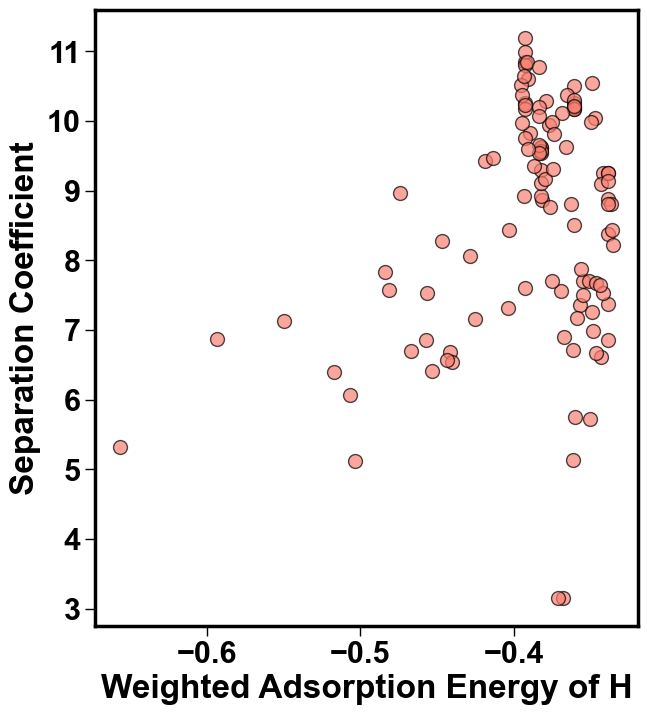

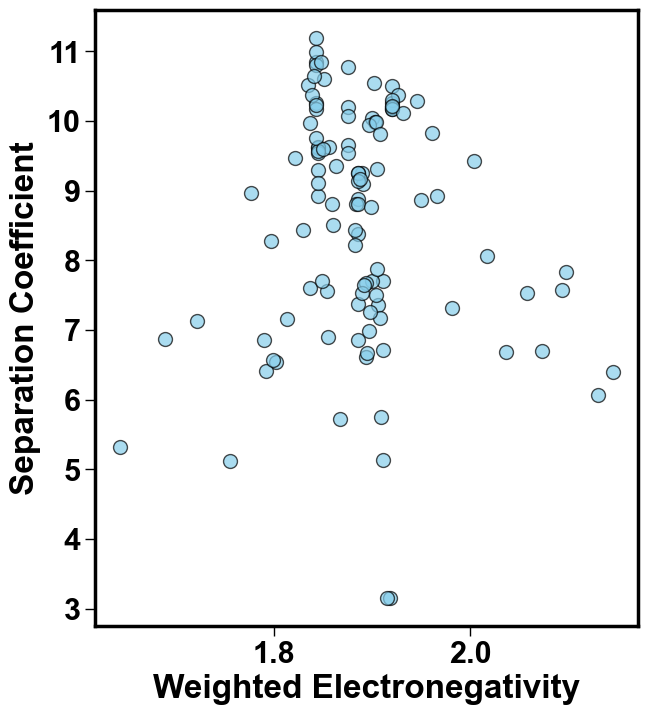

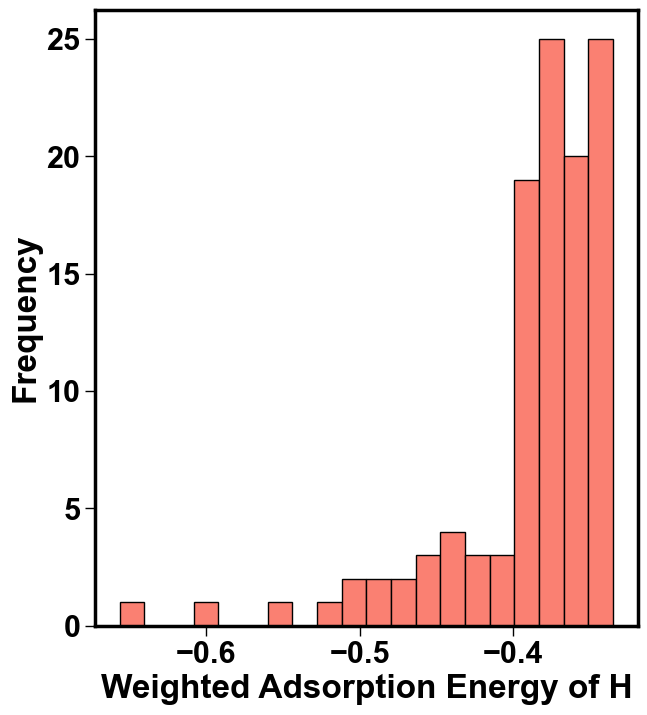

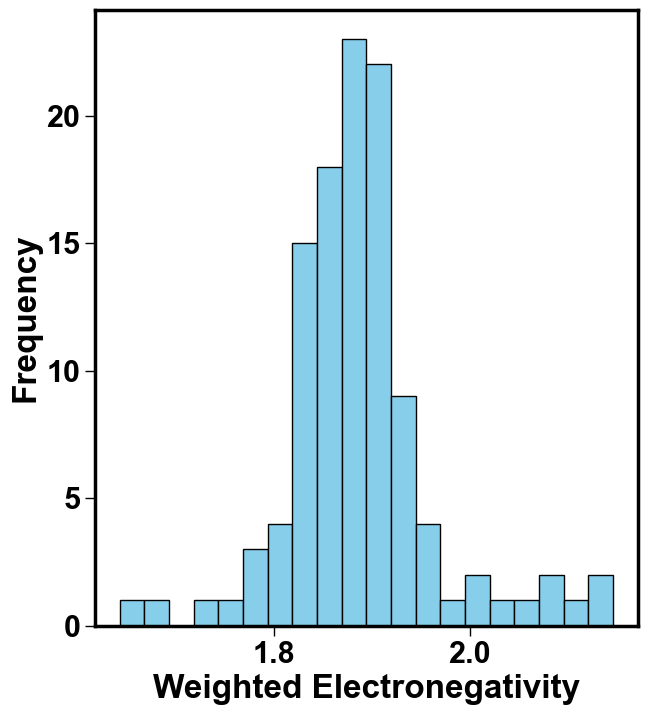

In [3]:
import matplotlib.pyplot as plt
# Set Arial Bold for all plot text elements (labels, ticks, titles)
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.weight'] = 'bold'
plt.rcParams['axes.linewidth'] = 2.5  # Increase the frame (border) thickness

# Set global settings for tick and label font size and weight
plt.rcParams['xtick.labelsize'] = 22  # Set the x-axis label size globally
plt.rcParams['ytick.labelsize'] = 22  # Set the y-axis label size globally
plt.rcParams['axes.labelsize'] = 26  # Set the axis label size globally
plt.rcParams['axes.labelweight'] = 'bold'  # Set the axis label weight to bold globally
plt.rcParams['xtick.major.width'] = 1.0  # Set the width of major x-ticks
plt.rcParams['ytick.major.width'] = 1.0  # Set the width of major y-ticks
plt.rcParams['xtick.major.size'] = 7  # Set the size of major x-ticks
plt.rcParams['ytick.major.size'] = 7  # Set the size of major y-ticks

# Now, when you create your plots, they will automatically apply these settings

# Subplot 1: Scatter plot of Weighted Adsorption Energy vs Separation Coefficient
plt.figure(figsize=(7, 8))
plt.scatter(plot_df["weighted_FE_ads_avg"], plot_df["separation_coefficient"], alpha=0.7, color='salmon', s=100, linewidths=1.0, edgecolors="black")
plt.xlabel("Weighted Adsorption Energy of H", fontsize=24, fontweight='bold')
plt.ylabel("Separation Coefficient", fontsize=24, fontweight='bold')
plt.savefig("scatter_plot_weighted_FE_ads_avg_vs_separation_coefficient.png", dpi=600, bbox_inches='tight')  # Save the first plot
plt.show()  # Show the first plot

# Subplot 2: Scatter plot of Weighted Electronegativity vs Separation Coefficient
plt.figure(figsize=(7, 8))
plt.scatter(plot_df["weighted_electronegativity"], plot_df["separation_coefficient"], alpha=0.7, color='skyblue', s=100, linewidths=1.0, edgecolors="black")
plt.xlabel("Weighted Electronegativity", fontsize=24, fontweight='bold')
plt.ylabel("Separation Coefficient", fontsize=24, fontweight='bold')
plt.savefig("scatter_plot_weighted_electronegativity_vs_separation_coefficient.png", dpi=600, bbox_inches='tight')  # Save the second plot
plt.show()  # Show the second plot

# Subplot 3: Histogram of Weighted Adsorption Energy
plt.figure(figsize=(7, 8))
plt.hist(plot_df["weighted_FE_ads_avg"], bins=20, color='salmon', edgecolor='black')
plt.xlabel("Weighted Adsorption Energy of H", fontsize=24, fontweight='bold')
plt.ylabel("Frequency", fontsize=24, fontweight='bold')
plt.savefig("histogram_weighted_FE_ads_avg.png", dpi=600, bbox_inches='tight')  # Save the third plot
plt.show()  # Show the third plot

# Subplot 4: Histogram of Weighted Electronegativity
plt.figure(figsize=(7, 8))
plt.hist(plot_df["weighted_electronegativity"], bins=20, color='skyblue', edgecolor='black')
plt.xlabel("Weighted Electronegativity", fontsize=24, fontweight='bold')
plt.ylabel("Frequency", fontsize=24, fontweight='bold')
plt.savefig("histogram_weighted_electronegativity.png", dpi=600, bbox_inches='tight')  # Save the fourth plot
plt.show()  # Show the fourth plot
